# 2.0 Which cost lines drive the deficits?

**Board question:** has income kept up with costs, and which cost lines grew fastest?

The analysis is done in SQL. Every query lives in
[`sql/analysis/02_cost_drivers.sql`](../../sql/analysis/02_cost_drivers.sql) and runs against the MySQL warehouse
(`nhs_gold` views and the `nhs_silver.fct_tac` fact table). Each section below shows the query exactly as
it is in that file, then its result. Python only runs the query and, in one place, draws a chart from the
result.

| Query | SQL technique |
| --- | --- |
| `income_vs_cost_growth` | Year range in a one-row CTE, two-year pivot |
| `surplus_bridge` | EAV pivot by SubCode, differences, bridge stacked with `UNION ALL` |
| `expense_line_growth` | Fact-to-dimension join, `SUM() OVER ()` share, `RANK()` |
| `pay_share_by_sector` | Median per group, then `LAG()` on the medians |
| `wte_data_quality` | Median per group joined back to detail rows as an anomaly rule |

**Data:** NHS England Trust Accounts Consolidation (TAC), annual and actuals only. Money is held in £000s;
columns ending `_m` are £m. Operating surplus is the SoCI line `SCI0140A` as each trust reported it, which
includes impairments (non-cash write-downs). No query is pinned to a year: each one reads the year range
from the data.

To run it: load the warehouse, `export DB_PASSWORD=...`, then run all cells.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Make analysis/nhs_analysis.py importable from the repo root or from this folder
here = Path.cwd()
sys.path.insert(0, str(here.parent if here.name == "notebooks" else here / "analysis"))
import nhs_analysis as nhs

nhs.set_style()
pd.options.display.float_format = "{:,.1f}".format
pd.options.display.max_columns = 20

## 2.1 Income growth against cost growth

The first and latest years come from a one-row CTE (`MIN`/`MAX` of `financial_year`), cross-joined in, so
the query never names a year. Conditional aggregation then turns the two years into columns.

In [2]:
nhs.sql("02_cost_drivers", "income_vs_cost_growth")

`sql/analysis/02_cost_drivers.sql` → **income_vs_cost_growth**

```sql
-- Growth in combined income and combined expenditure for each sector between the
-- first and latest year. A positive gap means costs outgrew income.
-- Technique: a one-row CTE holding the year range, then a pivot of two years
-- into columns with conditional aggregation.
WITH yrs AS (
    SELECT MIN(financial_year) AS first_year, MAX(financial_year) AS latest_year
    FROM nhs_silver.fct_tac
),
pivoted AS (
    SELECT
        s.sector,
        SUM(CASE WHEN s.financial_year = y.first_year  THEN s.total_income_000s      END) AS income_first,
        SUM(CASE WHEN s.financial_year = y.latest_year THEN s.total_income_000s      END) AS income_latest,
        SUM(CASE WHEN s.financial_year = y.first_year  THEN s.total_expenditure_000s END) AS cost_first,
        SUM(CASE WHEN s.financial_year = y.latest_year THEN s.total_expenditure_000s END) AS cost_latest
    FROM v_kpis s
    CROSS JOIN yrs y
    GROUP BY s.sector
)
SELECT
    sector,
    ROUND(100 * (income_latest / income_first - 1), 1)                        AS income_growth_pct,
    ROUND(100 * (cost_latest   / cost_first   - 1), 1)                        AS cost_growth_pct,
    ROUND(100 * (cost_latest / cost_first - income_latest / income_first), 1) AS growth_gap_pts
FROM pivoted
ORDER BY growth_gap_pts DESC;
```

,sector,income_growth_pct,cost_growth_pct,growth_gap_pts
0,Specialist,0.8,4.3,3.5
1,Mental Health,13.1,16.5,3.4
2,Acute,12.2,15.3,3.1
3,Ambulance,11.3,12.8,1.5
4,Community,11.5,12.8,1.3


## 2.2 Surplus bridge: from the first year's result to the latest

A bridge (or walk) explains a change in profit step by step. Every line is pivoted straight out of the
long fact table by SubCode: income (`SCI0100A` + `SCI0110A`), staff (`EXP0130`), drugs (`EXP0170`),
impairments (`EXP0260`), depreciation and amortisation (`EXP0240`, `EXP0250`) and total operating expense
(`EXP0390`). *All other operating costs* is the remainder of total expense, so the steps always add up
exactly to the change. The check below the table proves it.

In [3]:
bridge = nhs.sql("02_cost_drivers", "surplus_bridge")
bridge

`sql/analysis/02_cost_drivers.sql` → **surplus_bridge**

```sql
-- A bridge (walk) from the national operating result in the first year to the
-- latest year: how much each driver added or took away. The steps add up exactly
-- to the change, because operating surplus = income - total operating expense.
-- Technique: pivot SubCodes out of the long fact table, take first/latest
-- differences, and stack the bridge steps with UNION ALL.
WITH yrs AS (
    SELECT MIN(financial_year) AS first_year, MAX(financial_year) AS latest_year
    FROM nhs_silver.fct_tac
),
year_lines AS (
    SELECT
        f.financial_year,
        SUM(CASE WHEN f.sub_code IN ('SCI0100A', 'SCI0110A') THEN f.total_000s ELSE 0 END) AS income,
        SUM(CASE WHEN f.sub_code = 'EXP0130'                 THEN f.total_000s ELSE 0 END) AS staff,
        SUM(CASE WHEN f.sub_code = 'EXP0170'                 THEN f.total_000s ELSE 0 END) AS drugs,
        SUM(CASE WHEN f.sub_code = 'EXP0260'                 THEN f.total_000s ELSE 0 END) AS impairments,
        SUM(CASE WHEN f.sub_code IN ('EXP0240', 'EXP0250')   THEN f.total_000s ELSE 0 END) AS depreciation,
        SUM(CASE WHEN f.sub_code = 'EXP0390'                 THEN f.total_000s ELSE 0 END) AS total_cost
    FROM nhs_silver.fct_tac f
    CROSS JOIN yrs y
    WHERE f.financial_year IN (y.first_year, y.latest_year)
      AND f.sub_code IN ('SCI0100A', 'SCI0110A', 'EXP0130', 'EXP0170',
                         'EXP0260', 'EXP0240', 'EXP0250', 'EXP0390')
    GROUP BY f.financial_year
),
delta AS (
    SELECT
        MAX(CASE WHEN l.financial_year = y.first_year THEN l.income - l.total_cost END)  AS start_result,
        SUM(CASE WHEN l.financial_year = y.latest_year THEN 1 ELSE -1 END * l.income)       AS d_income,
        SUM(CASE WHEN l.financial_year = y.latest_year THEN 1 ELSE -1 END * l.staff)        AS d_staff,
        SUM(CASE WHEN l.financial_year = y.latest_year THEN 1 ELSE -1 END * l.drugs)        AS d_drugs,
        SUM(CASE WHEN l.financial_year = y.latest_year THEN 1 ELSE -1 END * l.impairments)  AS d_impairments,
        SUM(CASE WHEN l.financial_year = y.latest_year THEN 1 ELSE -1 END * l.depreciation) AS d_depreciation,
        SUM(CASE WHEN l.financial_year = y.latest_year THEN 1 ELSE -1 END * l.total_cost)   AS d_total_cost,
        MAX(CASE WHEN l.financial_year = y.latest_year THEN l.income - l.total_cost END) AS end_result
    FROM year_lines l
    CROSS JOIN yrs y
)
SELECT 1 AS step, CONCAT('Operating result ', (SELECT first_year FROM yrs)) AS bridge_step,
       ROUND(start_result / 1000, 1) AS amount_m FROM delta
UNION ALL SELECT 2, 'Income growth',                     ROUND( d_income / 1000, 1)       FROM delta
UNION ALL SELECT 3, 'Staff cost growth',                 ROUND(-d_staff / 1000, 1)        FROM delta
UNION ALL SELECT 4, 'Drugs cost growth',                 ROUND(-d_drugs / 1000, 1)        FROM delta
UNION ALL SELECT 5, 'Impairments growth (non-cash)',     ROUND(-d_impairments / 1000, 1)  FROM delta
UNION ALL SELECT 6, 'Depreciation and amortisation',     ROUND(-d_depreciation / 1000, 1) FROM delta
UNION ALL SELECT 7, 'All other operating costs',
       ROUND(-(d_total_cost - d_staff - d_drugs - d_impairments - d_depreciation) / 1000, 1)  FROM delta
UNION ALL SELECT 8, CONCAT('Operating result ', (SELECT latest_year FROM yrs)),
       ROUND(end_result / 1000, 1) FROM delta
ORDER BY step;
```

,step,bridge_step,amount_m
0,1,Operating result 2021/22,"1,690.1"
1,2,Income growth,"13,643.9"
2,3,Staff cost growth,"-10,707.9"
3,4,Drugs cost growth,"-1,426.1"
4,5,Impairments growth (non-cash),"-1,420.5"
5,6,Depreciation and amortisation,"-1,255.8"
6,7,All other operating costs,"-2,158.0"
7,8,Operating result 2023/24,"-1,634.3"


Sum of bridge steps: -3,324.4  |  change in result: -3,324.4  |  reconciles: True


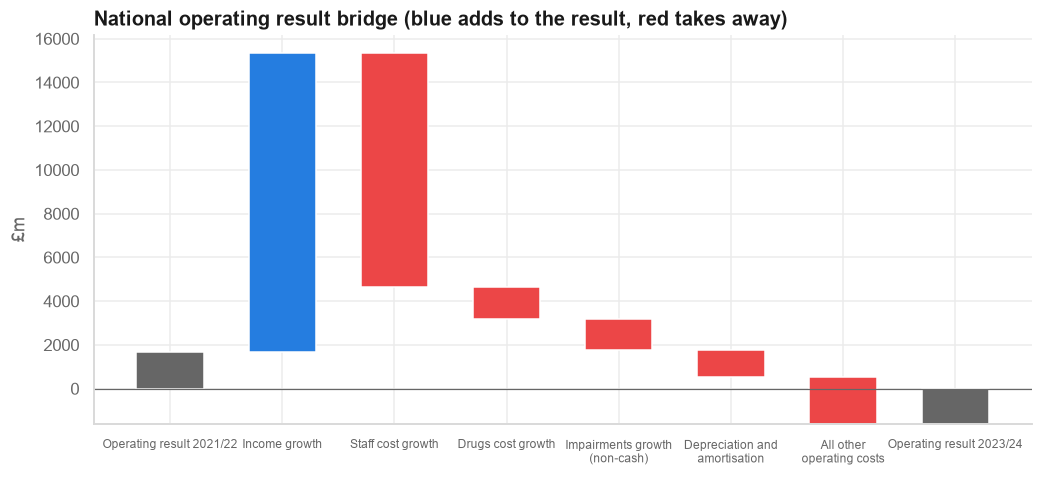

In [4]:
steps = bridge.amount_m.iloc[1:-1].sum()
change = bridge.amount_m.iloc[-1] - bridge.amount_m.iloc[0]
print(f"Sum of bridge steps: {steps:,.1f}  |  change in result: {change:,.1f}  |  reconciles: {abs(steps - change) < 0.5}")

# Waterfall chart drawn from the query result
start = bridge.amount_m.iloc[0]
bottoms, running = [], start
for v in bridge.amount_m.iloc[1:-1]:
    bottoms.append(running if v >= 0 else running + v)
    running += v
fig, ax = plt.subplots(figsize=(11, 4.6))
labels = bridge.bridge_step.str.replace(" (non-cash)", "\n(non-cash)", regex=False).str.replace(
    "Depreciation and amortisation", "Depreciation and\namortisation").str.replace("All other operating costs", "All other\noperating costs")
ax.bar(labels.iloc[0], start, color=nhs.TEXT_SECONDARY, width=0.6)
for lab, v, b in zip(labels.iloc[1:-1], bridge.amount_m.iloc[1:-1], bottoms):
    ax.bar(lab, abs(v), bottom=b, color=nhs.SURPLUS if v >= 0 else nhs.DEFICIT, width=0.6)
ax.bar(labels.iloc[-1], bridge.amount_m.iloc[-1], color=nhs.TEXT_SECONDARY, width=0.6)
ax.axhline(0, color=nhs.TEXT_SECONDARY, linewidth=0.8)
ax.set(title="National operating result bridge (blue adds to the result, red takes away)", ylabel="£m")
ax.tick_params(axis="x", labelsize=8)
plt.show()

## 2.3 Which expense lines grew the most

Every TAC08 operating-expense line, labelled through the SubCode dimension (`dim_subcode`) with subtotals
excluded. `SUM(...) OVER ()` puts the total cost increase on every row, so each line's share of it is one
division; `RANK()` orders them.

In [5]:
nhs.sql("02_cost_drivers", "expense_line_growth")

`sql/analysis/02_cost_drivers.sql` → **expense_line_growth**

```sql
-- Every TAC08 operating-expense line, ranked by its increase between the first
-- and latest year, with its share of the total cost increase.
-- Technique: join the fact table to the SubCode dimension for labels, pivot two
-- years, then SUM() OVER () for each line's share of the whole and RANK().
WITH yrs AS (
    SELECT MIN(financial_year) AS first_year, MAX(financial_year) AS latest_year
    FROM nhs_silver.fct_tac
),
by_line AS (
    SELECT
        sc.description                                                            AS line_item,
        sc.analytics_category,
        SUM(CASE WHEN f.financial_year = y.first_year  THEN f.total_000s ELSE 0 END) AS first_000s,
        SUM(CASE WHEN f.financial_year = y.latest_year THEN f.total_000s ELSE 0 END) AS latest_000s
    FROM nhs_silver.fct_tac f
    JOIN nhs_silver.dim_subcode sc ON sc.sub_code = f.sub_code
    CROSS JOIN yrs y
    WHERE f.worksheet_name = 'TAC08 Op Exp'
      AND sc.is_subtotal = 0
      AND f.financial_year IN (y.first_year, y.latest_year)
    GROUP BY sc.description, sc.analytics_category
)
SELECT
    RANK() OVER (ORDER BY latest_000s - first_000s DESC)                                    AS growth_rank,
    line_item,
    analytics_category,
    ROUND(latest_000s / 1000, 1)                                                            AS latest_m,
    ROUND((latest_000s - first_000s) / 1000, 1)                                             AS increase_m,
    ROUND(100 * (latest_000s / NULLIF(first_000s, 0) - 1), 1)                               AS growth_pct,
    ROUND(100 * (latest_000s - first_000s) / SUM(latest_000s - first_000s) OVER (), 1)      AS share_of_cost_increase_pct
FROM by_line
ORDER BY growth_rank
LIMIT 12;
```

,growth_rank,line_item,analytics_category,latest_m,increase_m,growth_pct,share_of_cost_increase_pct
0,1,Staff and executive directors costs,PAY,"81,807.8","10,707.9",15.1,61.4
1,2,Drugs costs,NON_PAY,"10,774.1","1,426.1",15.3,8.2
2,3,Impairments net of reversals,NON_PAY_EXCL_EBITDA,"2,120.9","1,420.5",202.8,8.1
3,4,Depreciation,NON_PAY_EXCL_EBITDA,"3,894.1","1,187.9",43.9,6.8
4,5,Supplies and services - clinical,NON_PAY,"9,391.5",992.1,11.8,5.7
5,6,Premises - other,NON_PAY,"4,676.9",507.0,12.2,2.9
6,7,Purchase of healthcare from non-NHS bodies,NON_PAY,"2,771.3",436.3,18.7,2.5
7,8,Supplies and services - general,NON_PAY,"1,987.0",164.9,9.0,0.9
8,9,Education and training - staff costs,PAY,394.1,123.6,45.7,0.7
9,10,Research and development - staff costs,PAY,548.5,113.5,26.1,0.7


## 2.4 Pay as a share of income

Two layers of window functions: `ROW_NUMBER()`/`COUNT() OVER` find the median trust in every sector and
year, then `LAG()` runs over those medians to give the year-on-year change.

In [6]:
nhs.sql("02_cost_drivers", "pay_share_by_sector")

`sql/analysis/02_cost_drivers.sql` → **pay_share_by_sector**

```sql
-- Pay as a share of income for the median trust in each sector, every year, and
-- the change on the year before.
-- Technique: median via ROW_NUMBER() and COUNT() OVER, then LAG() on the result,
-- two layers of window functions over two CTEs.
WITH ranked AS (
    SELECT
        sector,
        financial_year,
        pay_pct_income,
        ROW_NUMBER() OVER (PARTITION BY sector, financial_year ORDER BY pay_pct_income) AS rn,
        COUNT(*)     OVER (PARTITION BY sector, financial_year)                         AS n
    FROM v_kpis
    WHERE pay_pct_income IS NOT NULL
),
medians AS (
    SELECT sector, financial_year,
           AVG(CASE WHEN rn IN (FLOOR((n + 1) / 2), CEIL((n + 1) / 2)) THEN pay_pct_income END) AS median_pay_pct
    FROM ranked
    GROUP BY sector, financial_year
)
SELECT
    sector,
    financial_year,
    ROUND(median_pay_pct, 1)                                                       AS median_pay_pct,
    ROUND(median_pay_pct - LAG(median_pay_pct) OVER (PARTITION BY sector ORDER BY financial_year), 1)
                                                                                   AS change_pts
FROM medians
ORDER BY sector, financial_year;
```

,sector,financial_year,median_pay_pct,change_pts
0,Acute,2021/22,62.8,NaN
1,Acute,2022/23,64.7,1.9
2,Acute,2023/24,64.8,0.1
3,Ambulance,2021/22,70.8,NaN
4,Ambulance,2022/23,72.1,1.3
5,Ambulance,2023/24,71.3,-0.8
6,Community,2021/22,69.7,NaN
7,Community,2022/23,72.5,2.8
8,Community,2023/24,71.2,-1.3
9,Mental Health,2021/22,72.0,NaN


## 2.5 Data quality: why cost per WTE is not used

`v_kpis` computes cost per whole-time equivalent (WTE), but the TAC09 staff numbers are incomplete for
some trusts. This query flags any trust whose pay per reported WTE is more than three times its sector
median. The rule is deliberately conservative: most ambulance trusts under-report WTE, which inflates the
ambulance median itself, so only the most extreme cases pass the threshold. That is the reason this
analysis uses pay as a share of income instead.

In [7]:
nhs.sql("02_cost_drivers", "wte_data_quality")

`sql/analysis/02_cost_drivers.sql` → **wte_data_quality**

```sql
-- Why cost per WTE is not used: trusts whose reported whole-time-equivalent
-- staff (TAC09) cannot support their pay bill. Each trust's pay per WTE is
-- compared with its sector median; more than three times the median is flagged.
-- Technique: a median per group as a CTE, joined back to the detail rows, with
-- a ratio test as the anomaly rule.
WITH base AS (
    SELECT org_code, organisation_name, sector, financial_year,
           pay_000s, total_wte, pay_000s / NULLIF(total_wte, 0) AS pay_per_wte_000s
    FROM v_kpis
    WHERE total_wte > 0
),
ranked AS (
    SELECT b.*,
           ROW_NUMBER() OVER (PARTITION BY sector, financial_year ORDER BY pay_per_wte_000s) AS rn,
           COUNT(*)     OVER (PARTITION BY sector, financial_year)                           AS n
    FROM base b
),
medians AS (
    SELECT sector, financial_year,
           AVG(CASE WHEN rn IN (FLOOR((n + 1) / 2), CEIL((n + 1) / 2)) THEN pay_per_wte_000s END) AS median_pay_per_wte
    FROM ranked
    GROUP BY sector, financial_year
)
SELECT
    b.financial_year,
    b.sector,
    b.organisation_name,
    ROUND(b.pay_000s / 1000, 1)                         AS pay_m,
    ROUND(b.total_wte, 0)                               AS reported_wte,
    ROUND(b.pay_per_wte_000s, 1)                        AS pay_per_wte_000s,
    ROUND(b.pay_per_wte_000s / m.median_pay_per_wte, 1) AS times_sector_median
FROM base b
JOIN medians m ON m.sector = b.sector AND m.financial_year = b.financial_year
WHERE b.pay_per_wte_000s > 3 * m.median_pay_per_wte
ORDER BY b.financial_year, times_sector_median DESC;
```

,financial_year,sector,organisation_name,pay_m,reported_wte,pay_per_wte_000s,times_sector_median
0,2021/22,Mental Health,Tavistock and Portman NHS Foundation Trust,51.0,20,"2,548.8",15.1
1,2021/22,Ambulance,South East Coast Ambulance Service NHS Foundat...,217.2,9,"24,132.7",5.4
2,2021/22,Ambulance,London Ambulance Service NHS Trust,418.8,25,"16,752.2",3.8
3,2022/23,Mental Health,Tavistock and Portman NHS Foundation Trust,51.5,18,"2,859.4",15.0
4,2022/23,Ambulance,London Ambulance Service NHS Trust,455.6,28,"16,270.3",4.1
5,2022/23,Ambulance,East of England Ambulance Service NHS Trust,311.8,24,"12,989.8",3.3
6,2023/24,Mental Health,Tavistock and Portman NHS Foundation Trust,57.4,14,"4,098.3",20.9
